In [1]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from pandas.tseries.holiday import USFederalHolidayCalendar
from lightgbm import LGBMRegressor
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

df = pd.read_csv("data/daily_requests.csv", parse_dates=["day"])
s = df.set_index("day")["requests"]

In [3]:
from lightgbm import LGBMRegressor
from sklearn.linear_model import LinearRegression
def make_features(s):
    F = pd.DataFrame(index=s.index)
    F["lag1"] = s.shift(1)                       # вчера
    F["lag7"] = s.shift(7)                       # неделю назад
    F["lag14"] = s.shift(14)                     # две недели назад
    F["mean7"] = s.shift(1).rolling(7).mean()    # среднее за прошлые 7 дней

    holidays = USFederalHolidayCalendar().holidays(s.index.min(), s.index.max())
    F["is_holiday"] = s.index.isin(holidays).astype(int)

    dow = pd.get_dummies(s.index.dayofweek, prefix="dow", drop_first=True).astype(int)
    dow.index = s.index
    return F.join(dow)

X = make_features(s)
data = X.join(s.rename("y")).dropna()
print(data.shape)
data.head()

(1812, 12)


,lag1,lag7,lag14,mean7,is_holiday,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6,y
day,,,,,,,,,,,,
2021-01-15,7592.0,7628.0,5482.0,7436.428571,0,0,0,0,1,0,0,7097
2021-01-16,7097.0,6799.0,5933.0,7360.571429,0,0,0,0,0,1,0,6365
2021-01-17,6365.0,6591.0,5564.0,7298.571429,0,0,0,0,0,0,1,5977
2021-01-18,5977.0,8207.0,7885.0,7210.857143,1,0,0,0,0,0,0,6635
2021-01-19,6635.0,7803.0,8243.0,6986.285714,0,1,0,0,0,0,0,8967


In [4]:
train_part = data[:"2023-12-31"]
valid = data["2024-01-01":"2024-12-31"]
features = [c for c in data.columns if c != "y"]

configs = {
    "Простая": dict(n_estimators=200, learning_rate=0.05, num_leaves=7),
    "Средняя":   dict(n_estimators=400, learning_rate=0.05, num_leaves=15),
    "Сложная":   dict(n_estimators=800, learning_rate=0.03, num_leaves=31),
}

for name, params in configs.items():
    m = LGBMRegressor(random_state=42, verbose=-1, **params)
    m.fit(train_part[features], train_part["y"])
    p = m.predict(valid[features])
    print(f"{name}: MAE = {mae(valid['y'], p):.0f}")

Простая: MAE = 767
Средняя: MAE = 798
Сложная: MAE = 835


In [5]:
best_params = configs["Простая"]

train = data[:"2024-12-31"]
test = data["2025-01-01":]

gbm = LGBMRegressor(random_state=42, verbose=-1, **best_params)
gbm.fit(train[features], train["y"])
pred_gbm = gbm.predict(test[features])

lin = LinearRegression().fit(train[features], train["y"])
pred_lin = lin.predict(test[features])

for name, pred in [("Baseline 'как вчера'", test["lag1"]),
                   ("Линейная регрессия", pred_lin),
                   ("LightGBM", pred_gbm)]:
    print(f"{name}: MAE = {mae(test['y'], pred):.0f}, MAPE = {mape(test['y'], pred):.1f}%")

Baseline 'как вчера': MAE = 814, MAPE = 8.1%
Линейная регрессия: MAE = 651, MAPE = 6.3%
LightGBM: MAE = 711, MAPE = 6.8%


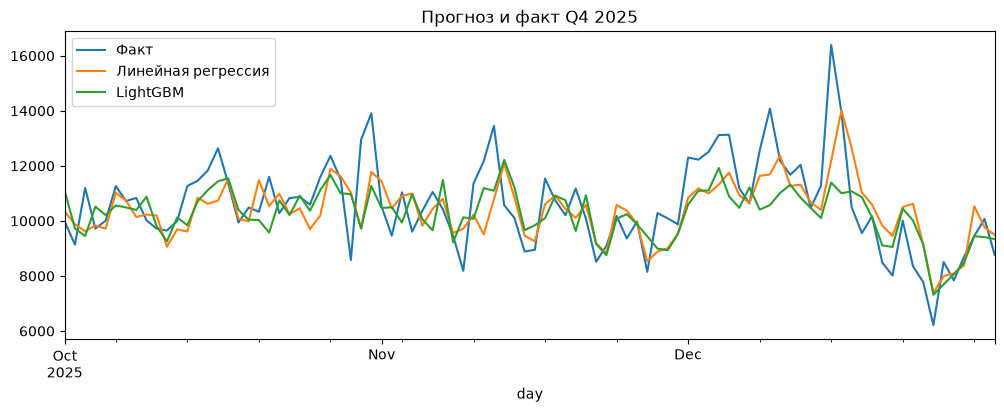

In [9]:
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Факт": test["y"],
    "Линейная регрессия": pred_lin,
    "LightGBM": pred_gbm,
}, index=test.index)

fig, ax = plt.subplots(figsize=(12, 4))
results["2025-10-01":"2025-12-31"].plot(ax=ax)
ax.set_title("Прогноз и факт Q4 2025")
fig.savefig("Files/forecast_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
results["Ошибки LR"] = (results["Факт"] - results["Линейная регрессия"]).abs()
print(results.nlargest(10, "Ошибки LR").round(0))

             Факт  Линейная регрессия  LightGBM  Ошибки LR
day                                                       
2025-12-15  16388             12185.0   11394.0     4203.0
2025-01-02  13811             10167.0   10538.0     3644.0
2025-01-21  13688             10135.0    9837.0     3553.0
2025-10-30  12946              9709.0    9731.0     3237.0
2025-06-24  14079             11226.0   10861.0     2853.0
2025-01-09  14906             12107.0   11382.0     2799.0
2025-11-12  13453             10782.0   11096.0     2671.0
2025-11-11  12172              9513.0   11188.0     2659.0
2025-01-07  15023             12412.0   10683.0     2611.0
2025-07-04  11265              8698.0    9643.0     2567.0


In [8]:
def make_features_v2(s):
    F = make_features(s)
    hol = USFederalHolidayCalendar().holidays(
        s.index.min() - pd.Timedelta(days=3),
        s.index.max() + pd.Timedelta(days=3))
    F["Перед праздником"] = s.index.isin(hol + pd.Timedelta(days=1)).astype(int)
    F["После праздника"] = s.index.isin(hol - pd.Timedelta(days=1)).astype(int)
    return F

def run(feature_fn, train_end, test_start, test_end):
    d = feature_fn(s).join(s.rename("y")).dropna()
    tr, te = d[:train_end], d[test_start:test_end]
    cols = [c for c in d.columns if c != "y"]
    lin = LinearRegression().fit(tr[cols], tr["y"])
    gbm = LGBMRegressor(random_state=42, verbose=-1, **configs["Простая"]).fit(tr[cols], tr["y"])
    return round(mae(te["y"], lin.predict(te[cols]))), round(mae(te["y"], gbm.predict(te[cols])))

for name, fn in [("v1", make_features), ("v2", make_features_v2)]:
    print(name, "Валидация 2024 (линейная, LightGBM):",
          run(fn, "2023-12-31", "2024-01-01", "2024-12-31"))

for name, fn in [("v1", make_features), ("v2", make_features_v2)]:
    print(name, "Тест 2025 (линейная, LightGBM):",
          run(fn, "2024-12-31", "2025-01-01", "2025-12-31"))

v1 Валидация 2024 (линейная, LightGBM): (691, 767)
v2 Валидация 2024 (линейная, LightGBM): (682, 770)
v1 Тест 2025 (линейная, LightGBM): (651, 711)
v2 Тест 2025 (линейная, LightGBM): (633, 699)
